# TMF static scene: single-pixel noise figure

This reproduces the output of `figure_generator.ipynb` using the migrated noise modules and the bundled TMF static-scene data. It plots one pixel through four stages with the same captions, stacked histogram style, depth marker, colors, and legend layout:

- `(a) Ideal impluse response`
- `(b) System Jitter and ambient noise`
- `(c) Dead-Time distortion`
- `(d) TDC DNL distortion`

The source notebook’s spelling of “impluse” is retained in the caption for compatibility.


In [27]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/synthetic_data_generation").is_dir()
             and (p / "examples/experiment_setting_example/tmf_static_simulation.json").is_file()), None)
if root is None:
    raise RuntimeError("Open this notebook from within the repository.")
sys.path.insert(0, str(root / "src"))
from spad_noise_injection.timestamps import (
    read_pixllized_timeStamp_from_h5, extract_pixel_timeStamp,
    get_timeStamp_count_sum_from_matrix, merge_pixelized_timeStamp,
)
from spad_noise_injection.time_jitter import create_emmision_jitter, add_zero_jitter
from spad_noise_injection.relaxation_delay import create_relaxation_delay, add_zero_relaxation_delay
from spad_noise_injection.ambient import create_ambient_timeStamp
from spad_noise_injection.dead_time import dead_time_simulation_rust
from spad_noise_injection.histogram import form_histogram_image_rust
from spad_noise_injection.depth import peak_found_center_of_mass
from spad_noise_injection.dnl import generate_random_dnl_matrix, extract_pixel_dnl

output = root / "examples/experiment_setting_example"
config = json.loads((output / "tmf_static_simulation.json").read_text())
histogram_options = next(stage["options"] for stage in config["stages"] if stage["command"] == "histogram")
input_min_range = float(histogram_options["min_range"])
input_bin_num = int(histogram_options["bin_number"])
input_bin_width = float(histogram_options["bin_width"])
input_max_range = input_min_range + input_bin_num * input_bin_width
pixel_x, pixel_y = 20,8 
pixels = read_pixllized_timeStamp_from_h5(str(output / "photons.h5"))
pixel_time_stamp = extract_pixel_timeStamp(pixel_x, pixel_y, pixels)
pixel_stamped_num = get_timeStamp_count_sum_from_matrix(pixel_time_stamp)

def make_histogram(pixelized, dnl_row=None):
    """Return the same three collision-based components used by the source figure."""
    dnl_matrix = None if dnl_row is None else np.asarray(dnl_row, dtype=float).reshape(1, 1, -1)
    illegal_info, stamped, true_path = form_histogram_image_rust(
        pixels=pixelized, bin_number=input_bin_num,
        range_distance=[input_min_range, input_max_range], dnl_matrix=dnl_matrix,
    )
    # form_histogram_image_rust returns (illegal, error, multi_path), stamped, true_path.
    # The source notebook calls collision_count < 0 "ambient" (stored in error).
    ambient = np.asarray(illegal_info[1])[0, 0, :].astype(float)
    multi_path = np.asarray(illegal_info[2])[0, 0, :].astype(float)
    true = np.asarray(true_path)[0, 0, :].astype(float)
    total = np.asarray(stamped)[0, 0, :].astype(float)
    return {"ambient": ambient, "multi_path": multi_path, "true_path": true, "total": total}

ideal_pixel = add_zero_relaxation_delay(add_zero_jitter(pixel_time_stamp))
pixel_histogram = make_histogram(ideal_pixel)

jittered = create_emmision_jitter(pixel_time_stamp, seeds_number=1, jitter_sigma=100,emission_mean=2300)
jittered = create_relaxation_delay(jittered, seeds_number=1, relaxation_tau=50)
ambient = create_ambient_timeStamp(
    diffuse_map_matrix=np.asarray([[1.0]]), num_timestamps=int(pixel_stamped_num * 1.2),
    min_range=input_min_range, max_range=input_max_range,
)
jittered = merge_pixelized_timeStamp(jittered, ambient)
jitter_histogram = make_histogram(jittered)

dead_time_timestamp, discard_num, accept_num = dead_time_simulation_rust(
    input_pixelized_timeStamp=jittered, pluse_train_num=2500,
    dead_time=13000, gap_time=1000000, active_cruch_time=True, random_seed=1,
)
dead_time_histogram = make_histogram(dead_time_timestamp)

dnl_matrix = generate_random_dnl_matrix(
    image_width=pixels.shape[1], image_height=pixels.shape[0],
    bin_number=input_bin_num, dnl_value=0.485, seed=1,
)
pixel_dnl = extract_pixel_dnl(pixel_x, pixel_y, dnl_matrix)[0, 0]
# Re-bin the dead-time components with the same DNL row used for the plot.
dnl_histogram = make_histogram(dead_time_timestamp, dnl_row=pixel_dnl)

print({"pixel": (pixel_x, pixel_y), "input_timestamps": int(pixel_stamped_num),
       "dead_time_discard": int(discard_num), "dead_time_accept": int(accept_num),
       "bin_count": input_bin_num, "bin_width": input_bin_width})


{'pixel': (20, 8), 'input_timestamps': 2546, 'dead_time_discard': 3325, 'dead_time_accept': 2276, 'bin_count': 64, 'bin_width': 100.0}


## Figure output

The bars use the same pastel category colors and labels as the source figure. Each component is populated from the timestamp collision count: blue background photons use `collision_count < 0`, yellow multipath photons use `collision_count > 2`, and green direct-reflect photons use `collision_count == 2`.

/tmp/ipykernel_943831/3183329110.py:37: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); return fig


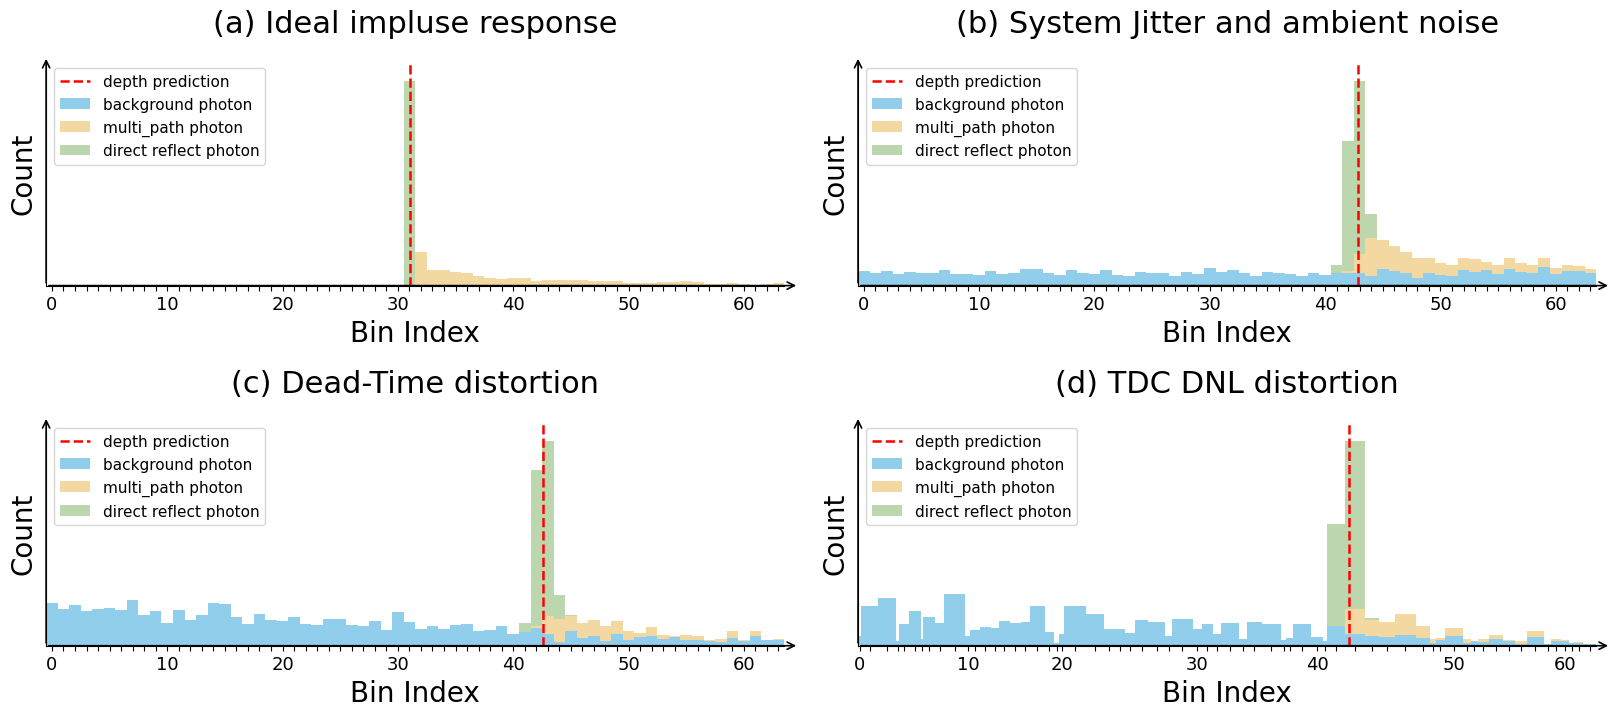

In [ ]:
histogram_inputs = [
    {"histogram": pixel_histogram, "title": "(a) Ideal impluse response"},
    {"histogram": jitter_histogram, "title": "(b) System Jitter and ambient noise"},
    {"histogram": dead_time_histogram, "title": "(c) Dead-Time distortion"},
    {"histogram": dnl_histogram, "title": "(d) TDC DNL distortion", "dnl_array": pixel_dnl},
]

def plot_histogram_categories(histogram_inputs):
    num_cols = 1 if len(histogram_inputs) == 1 else 2
    num_rows = int(np.ceil(len(histogram_inputs) / num_cols))
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(10 * num_cols, 3.8 * num_rows), squeeze=False, gridspec_kw={"wspace": 0.1, "hspace": 0.6})
    fig.patch.set_alpha(0.0)
    axes = axes.ravel()
    fig.subplots_adjust(wspace=2, hspace=1.35)
    for ax, item in zip(axes, histogram_inputs):
        histogram = item["histogram"]; dnl_array = item.get("dnl_array")
        ambient = histogram["ambient"]; multi_path = histogram["multi_path"]; true_path = histogram["true_path"]
        widths = np.ones(input_bin_num) if dnl_array is None else 1.0 + np.asarray(dnl_array, dtype=float).reshape(-1)
        left_edges = np.concatenate(([0.0], np.cumsum(widths[:-1]))); centers = left_edges + widths / 2.0
        multi_bottom = ambient; true_bottom = ambient + multi_path; total = true_bottom + true_path
        ambient_color = (145 / 255, 206 / 255, 236 / 255); multi_color = (244 / 255, 216 / 255, 162 / 255); true_color = (188 / 255, 214 / 255, 173 / 255)
        ax.bar(left_edges, ambient, width=widths, align="edge", label="background photon", color=ambient_color)
        ax.bar(left_edges, multi_path, width=widths, align="edge", bottom=multi_bottom, label="multi_path photon", color=multi_color)
        ax.bar(left_edges, true_path, width=widths, align="edge", bottom=true_bottom, label="direct reflect photon", color=true_color)
        depth_index = peak_found_center_of_mass(total)
        if 0 <= depth_index < total.shape[0]:
            depth_bin = min(int(np.floor(depth_index)), total.shape[0] - 1)
            ax.axvline(left_edges[depth_bin] + (depth_index - depth_bin) * widths[depth_bin], color="red", linestyle="--", linewidth=1.8, label="depth prediction")
        ax.set_xlim(left_edges[0], left_edges[-1] + widths[-1]); y_max = float(total.max()) if total.size else 1.0; ax.set_ylim(0, y_max * 1.1 if y_max > 0 else 1.0)
        ax.set_xticks(centers); ax.set_xticklabels([str(i) if i % 10 == 0 else "" for i in range(input_bin_num)])
        ax.text(0.5, 1.1, item["title"], transform=ax.transAxes, ha="center", va="bottom", fontsize=22)
        ax.set_ylabel("Count", rotation=90, labelpad=28, va="center", fontsize=20); ax.yaxis.set_label_coords(-0.03, 0.5); ax.set_xlabel("Bin Index", fontsize=20); ax.set_yticks([]); ax.set_facecolor("none"); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
        ax.annotate("", xy=(1.02, 0), xytext=(0, 0), xycoords="axes fraction", textcoords="axes fraction", arrowprops=dict(arrowstyle="->", color="black", lw=1.2), clip_on=False)
        ax.annotate("", xy=(0, 1.02), xytext=(0, 0), xycoords="axes fraction", textcoords="axes fraction", arrowprops=dict(arrowstyle="->", color="black", lw=1.2), clip_on=False)
        ax.legend(loc="upper left", ncols=1, fontsize=12)
    for ax in axes[len(histogram_inputs):]: ax.set_visible(False)
    plt.tight_layout(); return fig

fig = plot_histogram_categories(histogram_inputs)
fig.savefig(output / "noise_injection.png", format="png", dpi=180, bbox_inches="tight")
plt.show()
